# BiciMAD infrastructure evolution

This notebook follows how the physical BiciMAD network changed. It starts with the number of bicycles in the network, then the number of stations EMT listed in each status snapshot.


## 0. Setup


In [1]:
from __future__ import annotations

import os
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from matplotlib.ticker import MaxNLocator

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 140)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 4)
plt.rcParams["axes.titlesize"] = 12

HERE = Path.cwd().resolve()
ROOT = HERE
for _candidate in (HERE, *HERE.parents):
    if (_candidate / "src" / "bicimad" / "__init__.py").is_file():
        ROOT = _candidate
        break
sys.path.insert(0, str(ROOT / "src"))
os.chdir(ROOT)

from bicimad.config import (
    MADRID_TZ,
    ProjectConfig,
    _month_from_stem,
    discover_months,
    discover_status_files,
    discover_trip_files,
)
from bicimad.download import ensure_status_files, ensure_trip_files
from bicimad.ingest import (
    count_trips_in_progress,
    load_snapshot_station_counts,
    snapshot_docked_bikes,
    trip_intervals,
)

cfg = ProjectConfig()
print("project root:", cfg.root)


project root: C:\Users\jejoz\Coding\TFG\v1


## 1. Bicycles in the network over time

A bicycle counts as in the network when it is docked at a station or out on a trip. At snapshot time $t$

$$
B(t) = \sum_{s} d_s(t) + \bigl|\{\text{trips in progress at } t\}\bigr|.
$$

Here $d_s(t)$ is `dock_bikes` at station $s$ in the snapshot. The sum covers every listed station, including a station with `no_available` equal to 1. A missing `dock_bikes` counts as zero. A trip is in progress when its start is at or before $t$ and its end is after $t$. A trip with no end time is left out.

The plotted value is the median of $B(t)$ on each calendar day in Europe/Madrid. A day with no snapshot is a gap in the line. The code below downloads any status file or trip file that is not already on disk, then keeps the months present in both archives. Each month is counted on its own, and that month's trips are dropped before the next month is read.


EMT 2017: listing https://media.emtmadrid.es/-HoGTStPZeC


EMT 2017: archive has no station-status files.


EMT 2018: listing https://media.emtmadrid.es/-9iZNUjrjri


EMT 2019: listing https://media.emtmadrid.es/-WNgfSj2ZvC


EMT 2020: listing https://media.emtmadrid.es/-rkuBymuFJX


EMT 2021: listing https://media.emtmadrid.es/-BRk4rTaAdV


... (62 outputs left out)

2022-09: cached, 717 snapshots


2022-10: cached, 739 snapshots


2022-11: cached, 717 snapshots


2022-12: cached, 725 snapshots


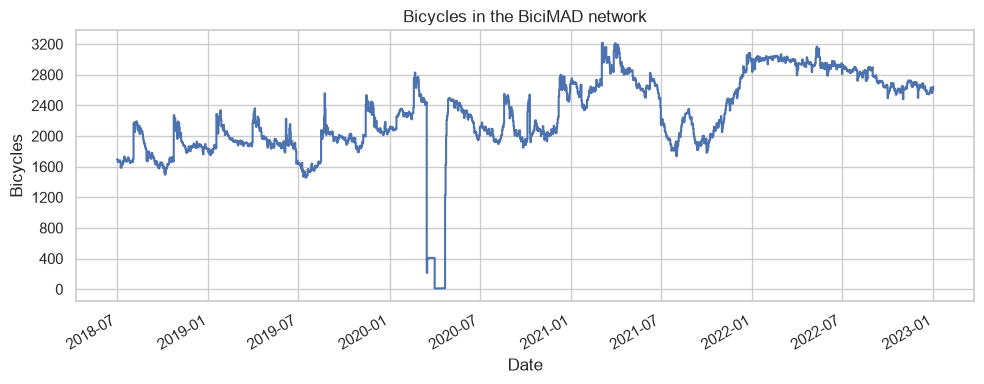

months used: 54 (2018-07 to 2022-12)
months: 2018-07, 2018-08, 2018-09, 2018-10, 2018-11, 2018-12, 2019-01, 2019-02, 2019-03, 2019-04, 2019-05, 2019-06, 2019-07, 2019-08, 2019-09, 2019-10, 2019-11, 2019-12, 2020-01, 2020-02, 2020-03, 2020-04, 2020-05, 2020-06, 2020-07, 2020-08, 2020-09, 2020-10, 2020-11, 2020-12, 2021-01, 2021-02, 2021-03, 2021-04, 2021-05, 2021-06, 2021-07, 2021-08, 2021-09, 2021-10, 2021-11, 2021-12, 2022-01, 2022-02, 2022-03, 2022-04, 2022-05, 2022-06, 2022-07, 2022-08, 2022-09, 2022-10, 2022-11, 2022-12
months inside that span without both files: none
snapshots: 39,252
first day 2018-07-01: 1695.0
last day 2023-01-01: 2643.0
minimum 10.0 on 2020-04-01
maximum 3217.5 on 2021-03-05


In [2]:
import json

status_report = ensure_status_files(cfg)
trip_report = ensure_trip_files(cfg)
print("status files:", status_report["action"].value_counts().to_dict())
print("trip files:", trip_report["action"].value_counts().to_dict())

months = discover_months(cfg)["both"]
if not months:
    raise RuntimeError("No month has both a status file and a trip file.")
status_files = discover_status_files(cfg)
trip_files = discover_trip_files(cfg)
missing_names = [
    path.name
    for path in sorted(cfg.trips_raw.iterdir())
    if path.is_file() and _month_from_stem(path.stem) is None
]
if missing_names:
    raise RuntimeError("Trip files with no month key: " + ", ".join(missing_names))

cache_dir = cfg.processed_dir / "infrastructure" / "bicycle_snapshots"
cache_dir.mkdir(parents=True, exist_ok=True)

frames = []
for month in months:
    status_path = status_files[month]
    trip_path = trip_files[month]
    cache = cache_dir / f"{month}.parquet"
    manifest_path = cache_dir / f"{month}.manifest.json"
    manifest = {
        "status": {"file": status_path.name, "bytes": status_path.stat().st_size},
        "trips": {"file": trip_path.name, "bytes": trip_path.stat().st_size},
    }
    if cache.is_file() and manifest_path.is_file():
        saved = json.loads(manifest_path.read_text(encoding="utf-8"))
        if saved == manifest:
            frame = pd.read_parquet(cache)
            frames.append(frame)
            print(f"{month}: cached, {len(frame):,} snapshots", flush=True)
            continue
    print(f"{month}: counting {status_path.name} and {trip_path.name}", flush=True)
    docked = snapshot_docked_bikes(status_path)
    start_ns, end_ns = trip_intervals(trip_path)
    riding = count_trips_in_progress(
        docked["ts"].astype("int64").to_numpy(),
        start_ns,
        end_ns,
    )
    frame = docked[["ts", "n_docked"]].copy()
    frame["n_riding"] = riding
    frame["n_bikes"] = frame["n_docked"].to_numpy() + riding
    frame["month"] = month
    frame.to_parquet(cache, index=False)
    manifest_path.write_text(json.dumps(manifest), encoding="utf-8")
    print(f"{month}: {len(frame):,} snapshots, {len(start_ns):,} trips", flush=True)
    del docked, start_ns, end_ns, riding
    frames.append(frame)

bikes = pd.concat(frames, ignore_index=True)


def _as_count(series: pd.Series) -> pd.Series:
    values = pd.to_numeric(series, errors="coerce")
    if values.dropna().empty or values.dropna().mod(1).eq(0).all():
        return values.round().astype("Int64")
    return values


local_day = bikes["ts"].dt.tz_convert(MADRID_TZ).dt.floor("D")
bike_daily = (
    bikes.assign(date=local_day)
    .groupby("date", as_index=False)
    .agg(n_bikes=("n_bikes", "median"))
    .sort_values("date")
    .reset_index(drop=True)
)
bike_daily["n_bikes"] = _as_count(bike_daily["n_bikes"])

calendar = pd.date_range(
    bike_daily["date"].min(), bike_daily["date"].max(), freq="D", tz=MADRID_TZ
)
bike_plot = bike_daily.set_index("date").reindex(calendar)

fig, ax = plt.subplots()
ax.step(bike_plot.index.tz_localize(None), bike_plot["n_bikes"], where="post")
ax.set_title("Bicycles in the BiciMAD network")
ax.set_xlabel("Date")
ax.set_ylabel("Bicycles")
ax.yaxis.set_major_locator(MaxNLocator(integer=True))
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

present = bike_plot["n_bikes"].dropna()
span = pd.period_range(months[0], months[-1], freq="M")
inside_missing = [str(period) for period in span if str(period) not in set(months)]
print(f"months used: {len(months)} ({months[0]} to {months[-1]})")
print("months:", ", ".join(months))
print("months inside that span without both files:", inside_missing or "none")
print(f"snapshots: {len(bikes):,}")
print(f"first day {present.index[0].strftime('%Y-%m-%d')}: {present.iloc[0]}")
print(f"last day {present.index[-1].strftime('%Y-%m-%d')}: {present.iloc[-1]}")
print(f"minimum {present.min()} on {present.idxmin().strftime('%Y-%m-%d')}")
print(f"maximum {present.max()} on {present.idxmax().strftime('%Y-%m-%d')}")


The daily median of $B(t)$ starts at 1,695 bicycles on 1 July 2018 and sits close to 2,500 in February 2020. On 16 March 2020 the docked count collapses. From 18 March through 31 March the median stays at 408: about 10 bicycles are still reported in the docks and about 398 are recorded as out on a trip in the March file. From 1 April through 18 April the median is 10, the bicycles still listed in the docks. The count climbs from 22 April and is back near 2,500 at the end of that month.

The highest daily median is 3,217.5 on 5 March 2021. A half bicycle is a day whose snapshots were split between two counts, so the median lies halfway between them. Through 2022 the median stays mostly between 2,600 and 3,000. The last point is 2,643 on 1 January 2023, from the single snapshot at the end of the December 2022 status file.

The series uses the 54 months that have both a status file and a trip file, July 2018 through December 2022. No calendar day from 1 July 2018 through 1 January 2023 is missing a snapshot.


## 2. Stations in the network over time

The EMT historical package publishes a snapshot of every station about once an hour. At snapshot time $t$ the size of the network is

$$
N(t) = |\{\text{stations listed in the EMT status snapshot at } t\}|.
$$

A station is active when the snapshot field `activate` equals 1. EMT can keep listing a station that is out of service, so the two counts are kept separate.

The plotted series is the median of each count inside a calendar day in Europe/Madrid. A day with no snapshot is a gap in the line. The download below takes only the station-status members of the 2017–2023 archives. Trip files stay on the server. A file already in `data/raw/status` is left as it is, and the snapshot counts are cached under `data/processed/infrastructure`.


In [3]:
report = ensure_status_files(cfg)
counts = load_snapshot_station_counts(cfg)

months = sorted(counts["month"].unique())
span = pd.period_range(months[0], months[-1], freq="M")
missing = [str(period) for period in span if str(period) not in set(months)]
unpublished = (
    report.loc[report["action"].eq("not published"), "year"].astype(int).tolist()
)
print(f"snapshots: {len(counts):,}")
print(f"status months: {months[0]} to {months[-1]} ({len(months)} months)")
print("months missing inside that span:", missing or "none")
print("yearly archives with no status files:", unpublished)


EMT 2017: listing https://media.emtmadrid.es/-HoGTStPZeC


EMT 2017: archive has no station-status files.


EMT 2018: listing https://media.emtmadrid.es/-9iZNUjrjri


EMT 2019: listing https://media.emtmadrid.es/-WNgfSj2ZvC


EMT 2020: listing https://media.emtmadrid.es/-rkuBymuFJX


EMT 2021: listing https://media.emtmadrid.es/-BRk4rTaAdV


EMT 2022: listing https://media.emtmadrid.es/-uHaW6iZkhG


EMT 2023: listing https://media.emtmadrid.es/-9Nii5DXo4x


EMT 2023: archive has no station-status files.


snapshots: 39,252
status months: 2018-07 to 2022-12 (54 months)
months missing inside that span: none
yearly archives with no status files: [2017, 2023]


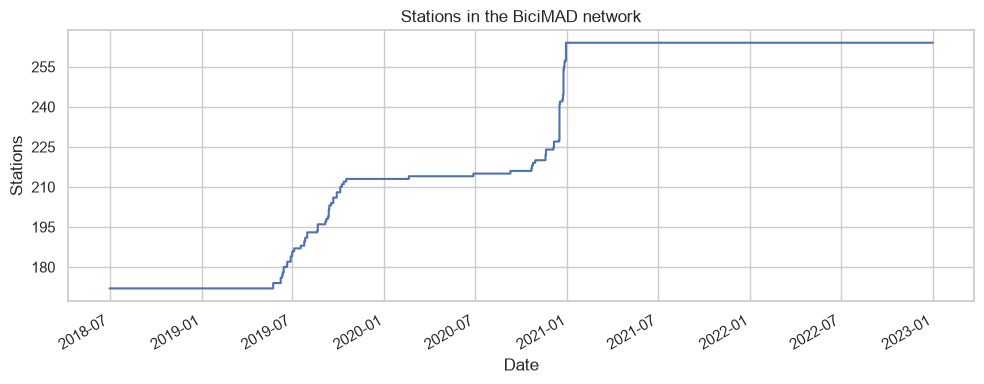

In [4]:
local_day = counts["ts"].dt.tz_convert(MADRID_TZ).dt.floor("D")
daily = (
    counts.assign(date=local_day)
    .groupby("date", as_index=False)
    .agg(n_stations=("n_stations", "median"), n_active=("n_active", "median"))
    .sort_values("date")
    .reset_index(drop=True)
)


def _as_count(series: pd.Series) -> pd.Series:
    values = pd.to_numeric(series, errors="coerce")
    if values.dropna().empty or values.dropna().mod(1).eq(0).all():
        return values.round().astype("Int64")
    return values


daily["n_stations"] = _as_count(daily["n_stations"])
daily["n_active"] = _as_count(daily["n_active"])

calendar = pd.date_range(daily["date"].min(), daily["date"].max(), freq="D", tz=MADRID_TZ)
plot = daily.set_index("date").reindex(calendar)
active_differs = bool(
    (
        plot["n_stations"].notna()
        & plot["n_active"].notna()
        & plot["n_stations"].ne(plot["n_active"])
    ).any()
)

fig, ax = plt.subplots()
x = plot.index.tz_localize(None)
ax.step(x, plot["n_stations"], where="post", label="Listed in the snapshot")
if active_differs:
    ax.step(x, plot["n_active"], where="post", label="Active (activate = 1)")
    ax.legend(frameon=False)
ax.set_title("Stations in the BiciMAD network")
ax.set_xlabel("Date")
ax.set_ylabel("Stations")
ax.yaxis.set_major_locator(MaxNLocator(integer=True))
fig.autofmt_xdate()
plt.tight_layout()
plt.show()


In [5]:
listed_changed = daily["n_stations"].diff().fillna(0).ne(0)
active_changed = daily["n_active"].diff().fillna(0).ne(0)
presence_changed = daily["n_active"].isna().astype(int).diff().fillna(0).ne(0)
changed = listed_changed | active_changed | presence_changed
changed.iloc[0] = True

changes = daily.loc[changed, ["date", "n_stations", "n_active"]].copy()
changes["change"] = changes["n_stations"].diff()
changes["date"] = changes["date"].dt.strftime("%Y-%m-%d")
changes = changes.rename(columns={"n_stations": "listed", "n_active": "active"})
changes


,date,listed,active,change
0,2018-07-01,172.0,172.0,<NA>
327,2019-05-24,174.0,174.0,2.0
342,2019-06-08,176.0,176.0,2.0
345,2019-06-11,177.0,177.0,1.0
346,2019-06-12,178.0,178.0,1.0
348,2019-06-14,180.0,180.0,2.0
354,2019-06-20,180.5,180.5,0.5
355,2019-06-21,182.0,182.0,1.5
362,2019-06-28,184.0,184.0,2.0
365,2019-07-01,185.5,185.5,1.5


## 3. Reading the series

From 1 July 2018 through 1 January 2023 the daily median rises from 172 stations to 264. Every step in the table is an increase. On every snapshot the active count equals the listed count, so `activate` is 1 for every station in these files.

The median stays at 172 until 24 May 2019. It then rises through the rest of 2019 and reaches 213 on 17 October 2019. The next additions are 214 on 19 February 2020, 215 on 27 June 2020, and 216 on 9 September 2020. From 21 October 2020 to 29 December 2020 the median climbs from 217 to 264. The largest one-day rises are 13.5 stations on 16 December 2020, to 241, then 9.5 on 24 December 2020, to 254, and 6.5 on 29 December 2020, to 264. A half station is a day whose hourly snapshots were split between two counts, so the median lies halfway between them. From 29 December 2020 through 1 January 2023 the median stays at 264. The table lists every day the median changes.

The status files cover every month from July 2018 through December 2022. The 2017 archive and the 2023 archive contain no station-status files, and the 2018 archive begins in July. No calendar day from 1 July 2018 through 1 January 2023 is missing a snapshot. The point on 1 January 2023 is the single snapshot at 00:57 local time at the end of the December 2022 file.
